# The σ (sigma-zero) attack — the thesis attack, developed

This is the notebook where the attack that the whole project converges on takes its final shape. σ-binary optimisation (the mature form of the sine idea from `03-attacks/cw_sine_lineage.ipynb`) is packaged here as a family of functions — `sigma_zero`, `sigma_zero2`, `sigma_zero3`, and the rounded variants — and then tuned: which function is best against each adversarially trained model, which **σ** (the smoothing width) works best, and which **rounding** scheme preserves the attack's success.

It closes with the final configuration run against all three models — the plain DNN, AT-PGD and AT-MaxMA — and a last refinement: filtering the gradient before normalising it.

**Where this fits:** Section 03 built the attacks; this section asks how the **defences** hold up against them — above all against the σ attack that grew out of `03-attacks/cw_sine_lineage.ipynb`. The same defences, measured in the final organised protocol, are `06-thesis-evaluation/`.

*Consolidated from `SigmaZero.ipynb` (originally in `PGD_form_attacks`). Outputs cleared.*

## Step 1 — Setup: data, the manipulation mask, and the shared scoring harness

# Loading data

In [ ]:
import torch

# Assuming you are using a GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

In [ ]:
import gdown

download_links = [
                  'https://drive.google.com/uc?id=1dkoFDyJMuGewWX-LE5rb7zkRU6XkSa2z',
                  'https://drive.google.com/uc?id=1oHJBbqyKybmlFFRZ7-uftn77Vg0Hr_A5',
                  'https://drive.google.com/uc?id=1YwxR5CCNnG5gjeFBlBA8mEfDQM22mLj_',
                  'https://drive.google.com/uc?id=1XB5jdefjnGSxrb27SO-65JZpz5UcsNh2',
                  'https://drive.google.com/uc?id=1Ahw4prIhm322LU53Yhkju5ixd6q1KCJ6',
                  'https://drive.google.com/uc?id=18_YhP6qHHmu52CfANYD2LqxrOzq5ECxl',
                  'https://drive.google.com/uc?id=140wKHyRpKurSuvEOswKdyH3kKRPg8VW_',
                  'https://drive.google.com/uc?id=1pTokv8xKvZoUo8kejJc7N757iNfHmt2s',
                  'https://drive.google.com/uc?id=107sDEWVIJZJWC1SIWASEepdRXB3VWlCZ',


]


output_filepath = '/content/'
for link in download_links:
  gdown.download(link, output_filepath)

In [ ]:
import zipfile

# Define the path to the zip file and the extraction path
zip_file_path = '/content/datasets.zip'
extract_to_path = '/content/'

# Unzip the file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset

# Load tensors
train_features = torch.load('train_features.pt', weights_only=True).float()
train_labels = torch.load('train_labels.pt', weights_only=True).long()
val_features = torch.load('val_features.pt', weights_only=True).float()
val_labels = torch.load('val_labels.pt', weights_only=True).long()
test_features = torch.load('test_features.pt', weights_only=True).float()
test_labels = torch.load('test_labels.pt', weights_only=True).long()

# Print data shapes for verification
print(f"Train Features Shape: {train_features.shape}")
print(f"Train Labels Shape: {train_labels.shape}")
print(f"Validation Features Shape: {val_features.shape}")
print(f"Validation Labels Shape: {val_labels.shape}")
print(f"Test Features Shape: {test_features.shape}")
print(f"Test Labels Shape: {test_labels.shape}")

# Create datasets
train_dataset = TensorDataset(train_features, train_labels)
val_dataset = TensorDataset(val_features, val_labels)
test_dataset = TensorDataset(test_features, test_labels)

# Set batch size
batch_size = 20000

# Create DataLoaders
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Optional: Verify DataLoader sizes
print('----------------------------------------------')
print(f"Train Loader Batch Count: {len(train_loader)}")
print(f"Validation Loader Batch Count: {len(val_loader)}")
print(f"Test Loader Batch Count: {len(test_loader)}")

In [ ]:
# Function to count samples for each label
def count_labels(labels):
    count_0 = (labels == 0).sum().item()  # Count samples with label = 0
    count_1 = (labels == 1).sum().item()  # Count samples with label = 1
    return count_0, count_1

# Count labels for each dataset
train_count_0, train_count_1 = count_labels(train_labels)
val_count_0, val_count_1 = count_labels(val_labels)
test_count_0, test_count_1 = count_labels(test_labels)

# Calculate total counts across all datasets
total_count_0 = train_count_0 + val_count_0 + test_count_0
total_count_1 = train_count_1 + val_count_1 + test_count_1

# Print results
print(f"Training set             \t Label 0: {train_count_0}\t Label 1: {train_count_1}")
print(f"Validation set           \t Label 0: {val_count_0}\t Label 1: {val_count_1}")
print(f"Test set                 \t Label 0: {test_count_0}\t Label 1: {test_count_1}")
print(f"Total across all datasets\t Label 0: {total_count_0}\t Label 1: {total_count_1}")

In [ ]:
print(f"The avrage number of feature in Training set: {train_features.sum()/train_features.shape[0]:.2f}")
print(f"The avrage number of feature in Validation set: {val_features.sum()/val_features.shape[0]:.2f}")
print(f"The avrage number of feature in Test set: {test_features.sum()/test_features.shape[0]:.2f}")

In [ ]:
removal_array = torch.load('manipulation_x.pt', weights_only=True, map_location=device)
removal_array.sum()

In [ ]:
import torch

def calculate_accuracy(model, test_loader, device='cpu'):
    """
    Calculate the accuracy of the model on the test dataset.

    Parameters:
    ----------
    model : nn.Module
        The trained model.
    test_loader : DataLoader
        The DataLoader containing the test dataset.
    device : str
        Device to run the model on ('cpu' or 'cuda').

    Returns:
    -------
    float
        The accuracy of the model on the test dataset.
    """
    # Set the model to evaluation mode
    model.eval()

    # Track the number of correct predictions
    correct_predictions = 0
    total_samples = 0

    # Disable gradient computation
    with torch.no_grad():
        for inputs, labels in test_loader:
            # Move data to the selected device
            inputs, labels = inputs.to(device), labels.to(device)

            # Forward pass
            outputs = model(inputs)

            # Get the predicted class (index of the highest logit value)
            _, predicted = torch.max(outputs, 1)

            # Count correct predictions
            correct_predictions += (predicted == labels).sum().item()
            total_samples += labels.size(0)

    # Calculate accuracy
    accuracy = correct_predictions / total_samples
    return accuracy

In [ ]:
def sum_of_top_n_differences(adv_rounded, mal_x_batch, y_pred, n):
    """
    Calculate the sum of the top n smallest differences between adv_rounded and mal_x_batch
    for samples where y_pred == 0.

    Parameters:
    adv_rounded (torch.Tensor): The rounded adversarial examples tensor.
    mal_x_batch (torch.Tensor): The original malicious examples tensor.
    y_pred (torch.Tensor): The prediction tensor.
    n (int): The number of top differences to sum.

    Returns:
    torch.Tensor: The sum of the top n smallest differences.
    """
    # Step 1: Calculate the total differences
    total_difference = torch.abs(adv_rounded[y_pred == 0] - mal_x_batch[y_pred == 0]).sum(1)

    # Step 2: Sort the differences in ascending order
    sorted_differences, _ = torch.sort(total_difference)

    # Step 3: Select the top n least differences
    top_n_least_differences = sorted_differences[:n]

    # Step 4: Sum these n differences
    sum_top_n_least_differences = top_n_least_differences.sum()

    return sum_top_n_least_differences

In [ ]:
import torch

def final_rounding(oimgs, newimg, model, removal_array):
    """
    Apply final rounding adjustments to adversarial images based on the model's predictions.

    Parameters:
    - oimgs (Tensor): Original images tensor.
    - newimg (Tensor): Adversarially perturbed images tensor.
    - model (nn.Module): The model used to evaluate active samples.
    - removal_array (Tensor): Array indicating features that should not be modified.

    Returns:
    - final (Tensor): The adjusted adversarial images.
    """

    # Ensure tensors are on the correct device
    device = oimgs.device
    oimgs, perturbed, removal_array = oimgs.to(device), newimg.to(device), removal_array.to(device)

    # Create mask for non-fixed features as a boolean tensor
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(oimgs.shape[0], -1), 1 - oimgs.to(torch.uint8)).bool()

    # Set the model to evaluation mode
    model.eval()

    # Calculate differences and prepare significant change mask
    with torch.no_grad():
        predictions = model(oimgs).argmax(dim=1)
        active_mask = predictions == 1
        total_change = (perturbed - oimgs).abs()
        significant_mask = total_change > 0.1
        sorted_idx = total_change.argsort(dim=1, descending=True)

        # Define changes to be applied, ensuring correct type and device
        changes = torch.where(perturbed > oimgs, 1, torch.where(perturbed < oimgs, 0, oimgs)).float().to(device)

    # Clone the original images for final adjustments
    final = oimgs.clone()

    # Set a practical maximum for significant changes per sample
    max_significant_changes = min(significant_mask.sum(dim=1).max().item(), 200)

    # Iterate through each significant change index
    for i in range(max_significant_changes):
        if not active_mask.any():
            break

        active_indices = torch.where(active_mask)[0]

        # Update the final image with changes based on non-fixed feature mask
        indices = sorted_idx[active_indices, i]
        final[active_indices, indices] = torch.where(
            non_fixed_features_mask[active_indices, indices],
            changes[active_indices, indices],
            final[active_indices, indices]
        )

        # Update active_mask based on model prediction after applying changes
        with torch.no_grad():
            active_mask[active_indices] = (model(final[active_indices]).argmax(dim=1) == 1)

    return final

In [ ]:
def evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model, removal_array, rounded=True):
    """
    Evaluate the model's performance on adversarial examples, optionally applying rounding.

    Parameters:
    - mal_x_batch (Tensor): Original malware input batch.
    - mal_y_batch (Tensor): Ground truth labels for malware batch.
    - adv (Tensor): Adversarial examples generated from mal_x_batch.
    - model (nn.Module): The trained model to be evaluated.
    - removal_array (Tensor): Array used for final rounding.
    - rounded (bool, optional): Whether to apply rounding on adversarial examples. Default is True.

    Returns:
    - final_adv (Tensor): The (rounded) adversarial examples used in evaluation.
    """

    # Set the model to evaluation mode
    model.eval()

    # Apply rounding if specified
    final_adv = final_rounding(mal_x_batch, adv, model, removal_array) if rounded else adv.clone()

    # Model predictions on adversarial examples
    with torch.no_grad():
        outputs = model(final_adv)
        y_pred = outputs.argmax(dim=1)

    # Evaluation metrics
    num_malwares = len(mal_y_batch)
    successful_attacks_mask = (y_pred == 0)
    num_successful_attacks = successful_attacks_mask.sum().item()

    # L1 norm differences for various evaluations
    def mean_l1_diff(adv_samples, orig_samples, top_n=None):
        if top_n is not None:
            return sum_of_top_n_differences(adv_samples, orig_samples, y_pred, top_n) / top_n
        return (torch.abs(adv_samples - orig_samples)).sum().item() / max(1, num_successful_attacks)

    # Only calculate for successful adversarial examples
    total_difference = mean_l1_diff(final_adv[successful_attacks_mask], mal_x_batch[successful_attacks_mask])
    total_difference_TOP500  = mean_l1_diff(final_adv, mal_x_batch, top_n=500)
    total_difference_TOP1000 = mean_l1_diff(final_adv, mal_x_batch, top_n=1000)
    total_difference_TOP2000 = mean_l1_diff(final_adv, mal_x_batch, top_n=2000)
    total_difference_TOP2500 = mean_l1_diff(final_adv, mal_x_batch, top_n=2500)

    # Accuracy
    accuracy = (y_pred == 1).sum().item() / num_malwares * 100

    # Print evaluation results
    print("Evaluation Results on Rounded Adversarial Examples")
    print("-----------------------------------------------")
    print(f"Number of malware samples: {num_malwares}")
    print(f"Number of successful attacks: {num_successful_attacks}")
    print(f"Mean difference (successful adv. examples vs. original): {total_difference:.2f}")
    print(f"Mean difference (successful adv. examples vs. original) - TOP 500   : {total_difference_TOP500:.2f}")
    print(f"Mean difference (successful adv. examples vs. original) - TOP 1000  : {total_difference_TOP1000:.2f}")
    print(f"Mean difference (successful adv. examples vs. original) - TOP 2000  : {total_difference_TOP2000:.2f}")
    print(f"Mean difference (successful adv. examples vs. original) - TOP 2500  : {total_difference_TOP2500:.2f}")
    print(f"Model accuracy on malware under attack: {accuracy:.2f}%")

    return final_adv

In [ ]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

def plot_adv_distances(adv_rounded_list, labels, model, mal_x_batch2, device):
    """
    Plots the cumulative distance between adversarial tensors and a reference batch (mal_x_batch2),
    with improved distinguishability for overlapping curves.
    """

    # Set a style and color palette
    sns.set(style='whitegrid')
    colors = sns.color_palette('husl', len(adv_rounded_list))  # Automatic color selection

    # Define line styles and markers for variety
    line_styles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'D', 'v']

    # Create the plot
    plt.figure(figsize=(30, 20))
    model.eval()

    # Iterate through each adv_rounded tensor and plot their distances
    for idx, (adv_rounded, color, label) in tqdm(enumerate(zip(adv_rounded_list, colors, labels)),
                                                  total=len(adv_rounded_list), desc="Processing Tensors"):
        # Move tensor to the correct device and get model predictions
        adv_rounded = adv_rounded.to(device)
        outputs = model(adv_rounded)
        y_pred = outputs.argmax(dim=1)

        # Calculate differences for correctly classified samples
        mal_x_batch2 = mal_x_batch2.to(device)
        total_difference = torch.sum((adv_rounded[y_pred == 0] - mal_x_batch2[y_pred == 0]) ** 2, dim=1)

        # Sort distances in ascending order
        sorted_differences, _ = torch.sort(total_difference)
        x_values = sorted_differences.cpu()
        y_values = torch.arange(1, len(sorted_differences) + 1).cpu()

        # Plot line with distinct line style and marker
        sns.lineplot(x=x_values, y=y_values, marker=markers[idx % len(markers)], color=color,
                     linestyle=line_styles[idx % len(line_styles)], linewidth=2, markersize=5, alpha=0.8, label=label)

    # Add labels and title
    plt.xlabel('Distance', fontsize=16, labelpad=10)
    plt.ylabel('Number of Valid Samples (Cumulative)', fontsize=16, labelpad=10)
    plt.title('Cumulative Count of Valid Samples vs. Distance', fontsize=18, pad=15)

    # Show legend and grid
    plt.legend(title='Adversarial Tensors', fontsize=12, title_fontsize=14, loc='upper left')
    plt.grid(True, linestyle='--', linewidth=0.5)
    sns.despine()

    # Show plot with tight layout
    plt.tight_layout()
    plt.show()

In [ ]:
def ensure_fixed_elements_unchanged(mal_x_batch, adv, adv_rounded, removal_array):
    """
    Ensure that fixed elements are not changed and calculate differences between adversarial examples and the original batch.

    Parameters:
    - mal_x_batch: Original malware input batch
    - adv: Adversarial examples generated from mal_x_batch
    - adv_rounded: Rounded adversarial examples
    - removal_array: Array indicating the fixed features

    Returns:
    - A dictionary containing differences for fixed and non-fixed features
    """

    # Ensure `removal_array` is expanded to match the batch size
    expanded_removal_array = removal_array.expand(mal_x_batch.shape[0], -1)

    # Create a mask where non-fixed features are set to 1
    non_fixed_features_mask = torch.bitwise_or(expanded_removal_array, 1 - mal_x_batch.to(torch.uint8))

    # Calculate indices where the mask is 0 (fixed) or 1 (non-fixed)
    mask_fixed = non_fixed_features_mask == 0
    mask_non_fixed = non_fixed_features_mask == 1

    # Calculate the differences for fixed and non-fixed features
    diff_adv_fixed = (torch.abs(adv - mal_x_batch) * mask_fixed).sum().item()
    diff_adv_non_fixed = (torch.abs(adv - mal_x_batch) * mask_non_fixed).sum().item()
    diff_adv_rounded_fixed = (torch.abs(adv_rounded - mal_x_batch) * mask_fixed).sum().item()
    diff_adv_rounded_non_fixed = (torch.abs(adv_rounded - mal_x_batch) * mask_non_fixed).sum().item()

    # Print the differences
    print(f"Differences when mask is 0 (fixed features):")
    print(f"  Adv vs. Original: {diff_adv_fixed}")
    print(f"  Rounded Adv vs. Original: {diff_adv_rounded_fixed}")
    print(f"Differences when mask is 1 (non-fixed features):")
    print(f"  Adv vs. Original: {diff_adv_non_fixed}")
    print(f"  Rounded Adv vs. Original: {diff_adv_rounded_non_fixed}")

    # Return the results as a dictionary
    return {
        "diff_adv_fixed": diff_adv_fixed,
        "diff_adv_non_fixed": diff_adv_non_fixed,
        "diff_adv_rounded_fixed": diff_adv_rounded_fixed,
        "diff_adv_rounded_non_fixed": diff_adv_rounded_non_fixed
    }

## Step 2 — The three models under attack

# Loading models and attacks

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MalwareDetectionDNN(nn.Module):
    def __init__(self, input_size, n_classes, device='cpu', name='DNN', **kwargs):
        """
        Construct malware detector

        Parameters
        ----------
        @param input_size: Integer, the dimentionality number of input vector
        @param n_classes: Integer, the number of classes, n=2
        @param device: String, 'cpu' or 'cuda'
        @param name: String, model name
        """
        super(MalwareDetectionDNN, self).__init__()
        self.input_size = input_size
        self.n_classes = n_classes
        self.device = device
        self.name = name

        self.parse_args(**kwargs)

        self.dense_layers = []
        if len(self.dense_hidden_units) >= 1:
            self.dense_layers.append(nn.Linear(self.input_size, self.dense_hidden_units[0]))
        else:
            raise ValueError("Expect at least one hidden layer.")
        for i in range(len(self.dense_hidden_units[0:-1])):
            self.dense_layers.append(nn.Linear(self.dense_hidden_units[i],  # start from idx=1
                                               self.dense_hidden_units[i + 1]))
        self.dense_layers.append(nn.Linear(self.dense_hidden_units[-1], self.n_classes))
        # registration
        for idx_i, dense_layer in enumerate(self.dense_layers):
            self.add_module('nn_model_layer_{}'.format(idx_i), dense_layer)

        if self.smooth:
            self.activation_func = F.selu  # partial(F.elu, alpha=self.alpha_)
        else:
            self.activation_func = F.relu


    def parse_args(self,
                   dense_hidden_units=None,
                   dropout=0.6,
                   alpha_=0.2,
                   smooth=False,
                   **kwargs
                   ):
        if dense_hidden_units is None:
            self.dense_hidden_units = [200, 200]
        elif isinstance(dense_hidden_units, list):
            self.dense_hidden_units = dense_hidden_units
        else:
            raise TypeError("Expect a list of hidden units.")

        self.dropout = dropout
        self.alpha_ = alpha_
        self.smooth = smooth
        self.proc_number = kwargs['proc_number']


    def forward(self, x):
        """
        Go through the neural network

        Parameters
        ----------
        @param x: 2D tensor, feature representation
        """
        for dense_layer in self.dense_layers[:-1]:
            x = self.activation_func(dense_layer(x))

        latent_representation = F.dropout(x, self.dropout, training=self.training)
        logits = self.dense_layers[-1](latent_representation)
        return logits


    def inference_batch_wise(self, x):
        """
        support malware samples solely
        """
        assert isinstance(x, torch.Tensor)
        logit = self.forward(x)
        return torch.softmax(logit, dim=-1).detach().cpu().numpy(), np.ones((logit.size()[0],))

In [ ]:
for x_test, y_test in test_loader:
      x_test, y_test = x_test.to(device), y_test.to(device)
      mal_x_batch, mal_y_batch = x_test[y_test.squeeze() == 1], y_test[y_test.squeeze() == 1]
      print(mal_x_batch.shape)
      print(mal_y_batch.shape)
      break

In [ ]:
model_dnn = MalwareDetectionDNN(10000,2,device=device,proc_number = 10)
model_dnn.load_state_dict(torch.load('/content/model_dnn.pth', map_location=torch.device(device)))
model_dnn.to(device)

# Calculate accuracy on the test set
test_accuracy = calculate_accuracy(model_dnn, test_loader, device)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

In [ ]:
model_at_pgd = MalwareDetectionDNN(10000,2,device=device,proc_number = 10)

# Load the saved dictionary from the file
checkpoint = torch.load('/content/model_at_pgd.pth', map_location=torch.device('cpu'))

# Extract the model's state_dict from the checkpoint
model_state_dict = checkpoint['model']

# Load the extracted state_dict into the model
model_at_pgd.load_state_dict(model_state_dict)

# Move model to device
model_at_pgd.to(device)

# Calculate accuracy on the test set
test_accuracy = calculate_accuracy(model_at_pgd, test_loader, device)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

In [ ]:
model_at_ma = MalwareDetectionDNN(10000,2,device=device,proc_number = 10)
# Load the saved dictionary from the file
checkpoint = torch.load('/content/model_at_ma.pth', map_location=torch.device('cpu'))

# Extract the model's state_dict from the checkpoint
model_state_dict = checkpoint['model']

# Load the extracted state_dict into the model
model_at_ma.load_state_dict(model_state_dict)

# Move model to device
model_at_ma.to(device)

# Calculate accuracy on the test set
test_accuracy = calculate_accuracy(model_at_ma, test_loader, device)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

## Step 3 — The plotting helpers

# Plots

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function parameters
x = np.linspace(0, 1, 1000)  # x values between 0 and 1

# Define the function
y = x**2 / (x**2 + 1e-6)
y2 = x**2 / (x**2 + 1e-5)
y3 = x**2 / (x**2 + 1e-4)
y4 = x**2 / (x**2 + 1e-3)

# Calculate the derivatives
dy_dx = np.gradient(y, x)
dy2_dx = np.gradient(y2, x)
dy3_dx = np.gradient(y3, x)
dy4_dx = np.gradient(y4, x)

# Plotting the original functions
plt.figure(figsize=(32, 16))
plt.subplot(2, 1, 1)
plt.plot(x, y, label=r"$\sigma = 1e-6$")
plt.plot(x, y2, label=r"$\sigma = 1e-5$")
plt.plot(x, y3, label=r"$\sigma = 1e-4$")
plt.plot(x, y4, label=r"$\sigma = 1e-3$")
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Plot of $\frac{x^2}{x^2 + \sigma}$ for different $\sigma$ values")
plt.legend()
plt.grid(True)

# Plotting the derivatives
plt.subplot(2, 1, 2)
plt.plot(x, dy_dx, label=r"Derivative for $\sigma = 1e-6$")
plt.plot(x, dy2_dx, label=r"Derivative for $\sigma = 1e-5$")
plt.plot(x, dy3_dx, label=r"Derivative for $\sigma = 1e-4$")
plt.plot(x, dy4_dx, label=r"Derivative for $\sigma = 1e-3$")
plt.xlabel("x")
plt.ylabel("dy/dx")
plt.title(r"Derivative of $\frac{x^2}{x^2 + \sigma}$ with respect to $x$")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function parameters
x = np.linspace(0, 0.1, 10000)  # x values between 0 and 1

# Define the function
y = x**2 / (x**2 + 1e-6)
y2 = x**2 / (x**2 + 1e-5)
y3 = x**2 / (x**2 + 1e-4)
y4 = x**2 / (x**2 + 1e-3)

# Calculate the derivatives
dy_dx = np.gradient(y, x)
dy2_dx = np.gradient(y2, x)
dy3_dx = np.gradient(y3, x)
dy4_dx = np.gradient(y4, x)

# Plotting the original functions
plt.figure(figsize=(32, 16))
plt.subplot(2, 1, 1)
plt.plot(x, y, label=r"$\sigma = 1e-6$")
plt.plot(x, y2, label=r"$\sigma = 1e-5$")
plt.plot(x, y3, label=r"$\sigma = 1e-4$")
plt.plot(x, y4, label=r"$\sigma = 1e-3$")
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"Plot of $\frac{x^2}{x^2 + \sigma}$ for different $\sigma$ values")
plt.legend()
plt.grid(True)

# Plotting the derivatives
plt.subplot(2, 1, 2)
plt.plot(x, dy_dx, label=r"Derivative for $\sigma = 1e-6$")
plt.plot(x, dy2_dx, label=r"Derivative for $\sigma = 1e-5$")
plt.plot(x, dy3_dx, label=r"Derivative for $\sigma = 1e-4$")
plt.plot(x, dy4_dx, label=r"Derivative for $\sigma = 1e-3$")
plt.xlabel("x")
plt.ylabel("dy/dx")
plt.title(r"Derivative of $\frac{x^2}{x^2 + \sigma}$ with respect to $x$")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function parameters
x = np.linspace(0, 1, 1000)  # x values between 0 and 1

# Calculate sparsity loss functions
sparsity_loss = np.tanh(4 * x)
sparsity_loss2 = np.tanh(8 * x)
sparsity_loss3 = np.tanh(16 * x)
sparsity_loss4 = np.tanh(32 * x)

# Calculate the derivatives
dsparsity_loss_dx = np.gradient(sparsity_loss, x)
dsparsity_loss2_dx = np.gradient(sparsity_loss2, x)
dsparsity_loss3_dx = np.gradient(sparsity_loss3, x)
dsparsity_loss4_dx = np.gradient(sparsity_loss4, x)

# Plot sparsity loss functions
plt.figure(figsize=(24, 16))
plt.subplot(2, 1, 1)
plt.plot(x, sparsity_loss, label=r"$\tanh(4x)$")
plt.plot(x, sparsity_loss2, label=r"$\tanh(8x)$")
plt.plot(x, sparsity_loss3, label=r"$\tanh(16x)$")
plt.plot(x, sparsity_loss4, label=r"$\tanh(32x)$")
plt.xlabel("Perturbation")
plt.ylabel("Sparsity-Inducing Loss")
plt.title("Sparsity-Inducing Loss for Different Coefficients")
plt.legend()
plt.grid(True)

# Plot derivatives of sparsity loss functions
plt.subplot(2, 1, 2)
plt.plot(x, dsparsity_loss_dx, label=r"Derivative of $\tanh(4x)$")
plt.plot(x, dsparsity_loss2_dx, label=r"Derivative of $\tanh(8x)$")
plt.plot(x, dsparsity_loss3_dx, label=r"Derivative of $\tanh(16x)$")
plt.plot(x, dsparsity_loss4_dx, label=r"Derivative of $\tanh(32x)$")
plt.xlabel("Perturbation")
plt.ylabel("d(Loss)/dx")
plt.title("Derivative of Sparsity-Inducing Loss with Respect to Perturbation")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Step 4 — The σ functions (three variants)

# Sigma zero

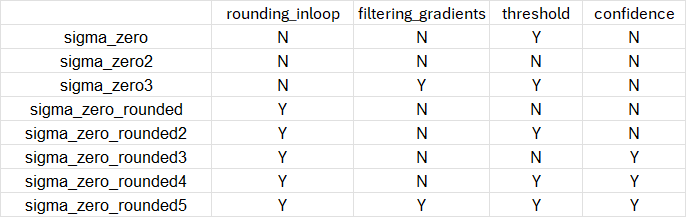

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10)

    # Track best perturbations
    best_l0 = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + 1e-4, min=0.0)

        # L0 approximation
        l0_approx = delta.square() / (delta.square() + sigma) # x^2/(x^2+sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features   # 1/d * l0_approx

        # Success mask and update best solutions
        with torch.no_grad():
            success_mask = logits.argmax(dim=1) == 0
            true_l0 = delta.data.ne(0).sum(dim=1)  # ne(0) (short for "not equal to zero")
            improved_mask = success_mask & (true_l0 < best_l0)

            best_l0 = torch.where(improved_mask, true_l0, best_l0)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for debugging
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            print(f"Iteration {step + 1:5}:\tLR = {scheduler.get_last_lr()[0]:.2f}\t"
                  f"Success = {success_mask.sum().item()}/{batch_size}\t"
                  f"Total Success = {success_samples.sum().item()}\t"
                  f"Best L0 (avg) = {best_l0[success_samples].float().mean().item():.2f}\t"
                  f"Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

            # Adjust threshold dynamically
            threshold_matrix[~success_mask] -= 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix[success_mask] += 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix.clamp_(0, 1)

            # Apply threshold filter to delta
            delta.data[delta.data.abs() < threshold_matrix] = 0

    return inputs + best_delta

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero2(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10)

    # Track best perturbations
    best_l0 = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + 1e-4, min=0.0)

        # L0 approximation
        l0_approx = delta.square() / (delta.square() + sigma) # x^2/(x^2+sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features   # 1/d * l0_approx

        # Success mask and update best solutions
        with torch.no_grad():
            success_mask = logits.argmax(dim=1) == 0
            true_l0 = delta.data.ne(0).sum(dim=1)  # ne(0) (short for "not equal to zero")
            improved_mask = success_mask & (true_l0 < best_l0)

            best_l0 = torch.where(improved_mask, true_l0, best_l0)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for debugging
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            print(f"Iteration {step + 1:5}:\tLR = {scheduler.get_last_lr()[0]:.2f}\t"
                  f"Success = {success_mask.sum().item()}/{batch_size}\t"
                  f"Total Success = {success_samples.sum().item()}\t"
                  f"Best L0 (avg) = {best_l0[success_samples].float().mean().item():.2f}\t"
                  f"Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

    return inputs + best_delta

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero3(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10)

    # Track best perturbations
    best_l0 = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + 1e-4, min=0.0)

        # L0 approximation
        l0_approx = delta.square() / (delta.square() + sigma) # x^2/(x^2+sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features   # 1/d * l0_approx

        # Success mask and update best solutions
        with torch.no_grad():
            success_mask = logits.argmax(dim=1) == 0
            true_l0 = delta.data.ne(0).sum(dim=1)  # ne(0) (short for "not equal to zero")
            improved_mask = success_mask & (true_l0 < best_l0)

            best_l0 = torch.where(improved_mask, true_l0, best_l0)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for debugging
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            print(f"Iteration {step + 1:5}:\tLR = {scheduler.get_last_lr()[0]:.2f}\t"
                  f"Success = {success_mask.sum().item()}/{batch_size}\t"
                  f"Total Success = {success_samples.sum().item()}\t"
                  f"Best L0 (avg) = {best_l0[success_samples].float().mean().item():.2f}\t"
                  f"Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        with torch.no_grad():
            # Gradient Filtering and normalization for stability
            gradients = delta.grad.data
            grad4removal = (gradients > 0) * (adv_inputs > 0.) * non_fixed_features_mask * gradients
            grad4insertion = (gradients < 0) *(adv_inputs < 1.)* gradients
            gradients = grad4removal + grad4insertion

            grad_norms = gradients.norm(p=grad_norm, dim=1, keepdim=True).clamp_(min=1e-12)
            gradients /= grad_norms
            delta.grad.data = gradients

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

            # Adjust threshold dynamically
            threshold_matrix[~success_mask] -= 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix[success_mask] += 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix.clamp_(0, 1)

            # Apply threshold filter to delta
            delta.data[delta.data.abs() < threshold_matrix] = 0

    return inputs + best_delta

## Step 5 — Which function is best for AT-PGD?

## best function for model_at_pgd

In [ ]:
adv = sigma_zero(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=False)
result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=True)

In [ ]:
adv2 = sigma_zero2(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded2 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv2, model_at_pgd, removal_array, rounded=False)
result_rounded2 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv2, model_at_pgd, removal_array, rounded=True)

In [ ]:
adv3 = sigma_zero3(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded3 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv3, model_at_pgd, removal_array, rounded=False)
result_rounded3 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv3, model_at_pgd, removal_array, rounded=True)

In [ ]:
adv_list = [result_non_rounded,result_non_rounded2,result_non_rounded3,result_rounded,result_rounded2,result_rounded3]  # Replace with your tensors
labels = ['sigma_zero','sigma_zero2','sigma_zero3','sigma_zero_rounded','sigma_zero_rounded2','sigma_zero_rounded3']  # Labels for the legend

plot_adv_distances(adv_list, labels, model_at_pgd, mal_x_batch, device)

## Step 6 — Which function is best for AT-MaxMA?

## best function for model_at_ma

In [ ]:
adv = sigma_zero(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=False)
result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=True)

In [ ]:
adv2 = sigma_zero2(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded2 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv2, model_at_ma, removal_array, rounded=False)
result_rounded2 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv2, model_at_ma, removal_array, rounded=True)

In [ ]:
adv3 = sigma_zero3(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded3 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv3, model_at_ma, removal_array, rounded=False)
result_rounded3 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv3, model_at_ma, removal_array, rounded=True)

In [ ]:
adv_list = [result_non_rounded,result_non_rounded2,result_non_rounded3,result_rounded,result_rounded2,result_rounded3]  # Replace with your tensors
labels = ['sigma_zero','sigma_zero2','sigma_zero3','sigma_zero_rounded','sigma_zero_rounded2','sigma_zero_rounded3']  # Labels for the legend

plot_adv_distances(adv_list, labels, model_at_ma, mal_x_batch, device)

## Step 7 — Finding the best σ

## best sigma

In [ ]:
adv_list = []
adv_rounded_list = []
sigmas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

# Loop through each sigma and collect results
for sigma in sigmas:

    print(f"{'*' * 150}\nEvaluating sigma = {sigma}")

    # Generate adversarial examples with current sigma
    adv = sigma_zero(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array.to(device), steps=5000, lr=1.0, sigma=sigma, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
    print()

    # Evaluate adversarial examples (original and rounded)
    result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=False)
    result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=True)

    adv_list.append(result_non_rounded)
    adv_rounded_list.append(result_rounded)

In [ ]:
# Define sigma values
sigmas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

# Construct adversarials_list and labels dynamically
adversarials_list = adv_list
labels = [f'notRounded_sigma={sigma}' for sigma in sigmas]

# Plot adversarial distances with generated lists and labels
plot_adv_distances(adv_list, labels, model_at_ma, mal_x_batch, device)

In [ ]:
# Define sigma values
sigmas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

# Construct adversarials_list and labels dynamically
adversarials_list = adv_list + adv_rounded_list
labels = [f'notRounded_sigma={sigma}' for sigma in sigmas] + [f'sigma={sigma}' for sigma in sigmas]

# Plot adversarial distances with generated lists and labels
plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)

## Step 8 — The rounding variants, and the best rounding per model

# Sigma zero - Rounding

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero_rounded(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        """Apply a mask on gradients to prevent updates to fixed features."""
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10)

    # Track best perturbations
    best_dist = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + 1e-4, min=0.0)

        # L0 approximation for sparsity
        l0_approx = delta.square() / (delta.square() + sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features

        # Determine non-rounded success mask
        success_mask_not_rounded = logits.argmax(dim=1) == 0

        # Evaluate rounded adversarial inputs at regular intervals
        if step == 0 or (step + 1) % 25 == 0:
          with torch.no_grad():
            adv_inputs_rounded = final_rounding(inputs, adv_inputs, model, removal_array)
            rounded_logits = model(adv_inputs_rounded)
            success_mask = rounded_logits.argmax(1) == 0

            # Calculate L0 distance for rounded inputs
            dist = torch.abs(inputs - adv_inputs_rounded).sum(dim=1)
            improved_mask = success_mask & (dist < best_dist)

            # Update best perturbations for successful samples
            best_dist = torch.where(improved_mask, dist, best_dist)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for tracking progress
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            avg_best_dist = best_dist[success_samples].float().mean().item() if success_samples.any() else float('nan')
            print(f"Iteration {step + 1:5} | LR = {scheduler.get_last_lr()[0]:.2f} | Success = {success_samples.sum().item()}/{batch_size} | Best Dist (avg) = {avg_best_dist:.2f} | Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

    return inputs + best_delta

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero_rounded2(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        """Apply a mask on gradients to prevent updates to fixed features."""
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10)

    # Track best perturbations
    best_dist = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + 1e-4, min=0.0)

        # L0 approximation for sparsity
        l0_approx = delta.square() / (delta.square() + sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features

        # Determine non-rounded success mask
        success_mask_not_rounded = logits.argmax(dim=1) == 0

        # Evaluate rounded adversarial inputs at regular intervals
        if step == 0 or (step + 1) % 25 == 0:
          with torch.no_grad():
            adv_inputs_rounded = final_rounding(inputs, adv_inputs, model, removal_array)
            rounded_logits = model(adv_inputs_rounded)
            success_mask = rounded_logits.argmax(1) == 0

            # Calculate L0 distance for rounded inputs
            dist = torch.abs(inputs - adv_inputs_rounded).sum(dim=1)
            improved_mask = success_mask & (dist < best_dist)

            # Update best perturbations for successful samples
            best_dist = torch.where(improved_mask, dist, best_dist)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for tracking progress
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            avg_best_dist = best_dist[success_samples].float().mean().item() if success_samples.any() else float('nan')
            print(f"Iteration {step + 1:5} | LR = {scheduler.get_last_lr()[0]:.2f} | Success = {success_samples.sum().item()}/{batch_size} | Best Dist (avg) = {avg_best_dist:.2f} | Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

            # Adjust threshold dynamically
            threshold_matrix[~success_mask_not_rounded] -= 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix[success_mask_not_rounded] += 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix.clamp_(0, 1)

            # Apply threshold filter to delta
            delta.data[delta.data.abs() < threshold_matrix] = 0

    return inputs + best_delta

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero_rounded3(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        """Apply a mask on gradients to prevent updates to fixed features."""
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10.)

    # Track best perturbations
    best_dist = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    confidence = torch.ones(batch_size, device=device) * 1e-4

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Evaluate rounded adversarial inputs at regular intervals
        if step == 0 or (step + 1) % 25 == 0:
          with torch.no_grad():
            # Determine non-rounded success mask
            success_mask_not_rounded = logits.argmax(dim=1) == 0

            adv_inputs_rounded = final_rounding(inputs, adv_inputs, model, removal_array)
            rounded_logits = model(adv_inputs_rounded)
            success_mask = rounded_logits.argmax(1) == 0

            # Calculate distance for rounded inputs
            dist = torch.abs(inputs - adv_inputs_rounded).sum(dim=1)
            improved_mask = success_mask & (dist < best_dist)

            # Update best perturbations for successful samples
            best_dist = torch.where(improved_mask, dist, best_dist)
            best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
            success_samples |= success_mask

            confidence[success_mask_not_rounded & success_mask] -= 0.05
            confidence[success_mask_not_rounded & ~success_mask] += 0.1
            confidence[~success_mask_not_rounded & ~success_mask] = 1e-4


        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + confidence, min=0.0)

        # L0 approximation for sparsity
        l0_approx = delta.square() / (delta.square() + sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for tracking progress
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            avg_best_dist = best_dist[success_samples].float().mean().item() if success_samples.any() else float('nan')
            print(f"Iteration {step + 1:5} | LR = {scheduler.get_last_lr()[0]:.2f} | Success = {success_samples.sum().item()}/{batch_size} | Best Dist (avg) = {avg_best_dist:.2f} | Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

    return inputs + best_delta

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero_rounded4(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        """Apply a mask on gradients to prevent updates to fixed features."""
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10.)

    # Track best perturbations
    best_dist = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    confidence = torch.ones(batch_size, device=device) * 1e-4

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Determine non-rounded success mask
        success_mask_not_rounded = logits.argmax(dim=1) == 0


        # Evaluate rounded adversarial inputs at regular intervals
        if step == 0 or (step + 1) % 25 == 0:
            with torch.no_grad():
                adv_inputs_rounded = final_rounding(inputs, adv_inputs, model, removal_array)
                rounded_logits = model(adv_inputs_rounded)
                success_mask = rounded_logits.argmax(1) == 0

                # Calculate L0 distance for rounded inputs
                dist = torch.abs(inputs - adv_inputs_rounded).sum(dim=1)
                improved_mask = success_mask & (dist < best_dist)

                # Update best perturbations for successful samples
                best_dist = torch.where(improved_mask, dist, best_dist)
                best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
                success_samples |= success_mask

                confidence[success_mask_not_rounded & success_mask] -= 0.05
                confidence[success_mask_not_rounded & ~success_mask] += 0.1
                confidence[~success_mask_not_rounded & ~success_mask] = 1e-4


        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + confidence, min=0.0)

        # L0 approximation for sparsity
        l0_approx = delta.square() / (delta.square() + sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for tracking progress
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            avg_best_dist = best_dist[success_samples].float().mean().item() if success_samples.any() else float('nan')
            print(f"Iteration {step + 1:5} | LR = {scheduler.get_last_lr()[0]:.2f} | Success = {success_samples.sum().item()}/{batch_size} | Best Dist (avg) = {avg_best_dist:.2f} | Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        # Gradient normalization for stability
        delta_grad = delta.grad.flatten(1)
        grad_norms = delta_grad.norm(p=grad_norm, dim=1, keepdim=True).clamp_min(1e-12)
        delta.grad = (delta_grad / grad_norms).view_as(delta.grad)

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

            # Adjust threshold dynamically
            threshold_matrix[~success_mask_not_rounded] -= 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix[success_mask_not_rounded] += 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix.clamp_(0, 1)

            # Apply threshold filter to delta
            delta.data[delta.data.abs() < threshold_matrix] = 0

    return inputs + best_delta

## best rounding function for model_at_ma


In [ ]:
# Define the sigma-zero functions and their names in a list for iteration
sigma_functions = [
    ("sigma_zero_rounded", sigma_zero_rounded),
    ("sigma_zero_rounded2", sigma_zero_rounded2),
    ("sigma_zero_rounded3", sigma_zero_rounded3),
    ("sigma_zero_rounded4", sigma_zero_rounded4)
]

# Initialize lists to store results
adv_examples = {}
results_non_rounded = {}
results_rounded = {}

# Run each sigma function and store results
for name, sigma_func in sigma_functions:
    print('***********************************************************************')
    print(f"Running {name}...")
    # Generate adversarial example
    adv_example = sigma_func(
        model_at_ma, mal_x_batch, removal_array,
        steps=4000, lr=1.0, sigma=1e-4, threshold=0.3,
        verbose=True, grad_norm=torch.inf, device=device
    )

    # Evaluate without rounding
    results_non_rounded[name] = evaluate_adversarial_examples(
        mal_x_batch, mal_y_batch, adv_example, model_at_ma,
        removal_array, rounded=False
    )

    # Evaluate with rounding
    results_rounded[name] = evaluate_adversarial_examples(
        mal_x_batch, mal_y_batch, adv_example, model_at_ma,
        removal_array, rounded=True
    )

    # Store adversarial example for reference if needed
    adv_examples[name] = adv_example

# At this point, results_non_rounded and results_rounded contain evaluation results for each function

In [ ]:
adv = sigma_zero(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=False)
result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=True)

In [ ]:
# Generate lists for plotting
adversarials_list = []
labels = []

adversarials_list.append(result_non_rounded)
labels.append(f"sigma_zero_refrence")


adversarials_list.append(result_rounded)
labels.append(f"sigma_zero_rounded_refrence")

# Populate lists with non-rounded and rounded adversarial examples for each function
for name in sigma_functions:

    # Rounded examples
    adversarials_list.append(results_rounded[name[0]])
    labels.append(name[0])

# Plot adversarial distances
plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)

In [ ]:
# Define the sigma-zero functions and their names in a list for iteration
top_sigma_functions = [
    ("sigma_zero_rounded2", sigma_zero_rounded2),
    ("sigma_zero_rounded4", sigma_zero_rounded4)
]

# Generate lists for plotting
adversarials_list = []
labels = []

adversarials_list.append(result_non_rounded)
labels.append(f"sigma_zero_refrence")


adversarials_list.append(result_rounded)
labels.append(f"sigma_zero_rounded_refrence")

# Populate lists with non-rounded and rounded adversarial examples for each function
for name in top_sigma_functions:

    # Rounded examples
    adversarials_list.append(results_rounded[name[0]])
    labels.append(name[0])

# Plot adversarial distances
plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)

## best rounding function for model_at_pgd

In [ ]:
# Define the sigma-zero functions and their names in a list for iteration
sigma_functions = [
    ("sigma_zero_rounded", sigma_zero_rounded),
    ("sigma_zero_rounded2", sigma_zero_rounded2),
    ("sigma_zero_rounded3", sigma_zero_rounded3),
    ("sigma_zero_rounded4", sigma_zero_rounded4)
]

# Initialize lists to store results
adv_examples = {}
results_rounded = {}

# Run each sigma function and store results
for name, sigma_func in sigma_functions:
    print(f"Running {name}...")
    # Generate adversarial example
    adv_example = sigma_func(
        model_at_pgd, mal_x_batch, removal_array,
        steps=4000, lr=1.0, sigma=1e-4, threshold=0.3,
        verbose=True, grad_norm=torch.inf, device=device
    )

    # Evaluate with rounding
    results_rounded[name] = evaluate_adversarial_examples(
        mal_x_batch, mal_y_batch, adv_example, model_at_pgd,
        removal_array, rounded=True
    )

    # Store adversarial example for reference if needed
    adv_examples[name] = adv_example

# At this point, results_non_rounded and results_rounded contain evaluation results for each function

In [ ]:
adv = sigma_zero(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=False)
result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=True)

In [ ]:
# Generate lists for plotting
adversarials_list = []
labels = []

adversarials_list.append(result_non_rounded)
labels.append(f"sigma_zero_refrence")


adversarials_list.append(result_rounded)
labels.append(f"sigma_zero_rounded_refrence")

# Populate lists with non-rounded and rounded adversarial examples for each function
for name in sigma_functions:

    # Rounded examples
    adversarials_list.append(results_rounded[name[0]])
    labels.append(name[0])

# Plot adversarial distances
plot_adv_distances(adversarials_list, labels, model_at_pgd, mal_x_batch, device)

In [ ]:
# Define the sigma-zero functions and their names in a list for iteration
top_sigma_functions = [
    ("sigma_zero_rounded2", sigma_zero_rounded2),
    ("sigma_zero_rounded4", sigma_zero_rounded4)
]

# Generate lists for plotting
adversarials_list = []
labels = []

adversarials_list.append(result_non_rounded)
labels.append(f"sigma_zero_refrence")


adversarials_list.append(result_rounded)
labels.append(f"sigma_zero_rounded_refrence")

# Populate lists with non-rounded and rounded adversarial examples for each function
for name in top_sigma_functions:

    # Rounded examples
    adversarials_list.append(results_rounded[name[0]])
    labels.append(name[0])

# Plot adversarial distances
plot_adv_distances(adversarials_list, labels, model_at_pgd, mal_x_batch, device)

## Step 9 — Finding the best σ, with rounding

## Finding best sigma

In [ ]:
adv_list = []
adv_rounded_list = []
sigmas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

# Loop through each sigma and collect results
for sigma in sigmas:

    print(f"{'*' * 150}\nEvaluating sigma = {sigma}")

    # Generate adversarial examples with current sigma
    adv = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array.to(device), steps=4000, lr=1.0, sigma=sigma, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
    print()

    # Evaluate adversarial examples (original and rounded)
    #result_non_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=False)
    result_rounded = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=True)

    adv_rounded_list.append(result_rounded)

In [ ]:
# Define sigma values
sigmas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]

# Construct adversarials_list and labels dynamically
adversarials_list = adv_rounded_list
labels = [f'sigma={sigma}' for sigma in sigmas]

# Plot adversarial distances with generated lists and labels
plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)

## Step 10 — Final results: DNN, AT-PGD, AT-MaxMA

# Final Results

## model_dnn

In [ ]:
adv = sigma_zero(model=model_dnn, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_dnn, removal_array, rounded=False)
result_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_dnn, removal_array, rounded=True)

In [ ]:
adv4 = sigma_zero_rounded4(model=model_dnn, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_dnn, removal_array, rounded=True)

In [ ]:
adversarials_list = [result_non_rounded_refrence, result_rounded_refrence, result_rounded_best]
labels = ['result_non_rounded_refrence', 'result_rounded_refrence', 'result_rounded_best']

plot_adv_distances(adversarials_list, labels, model_dnn, mal_x_batch, device)

## model_at_pgd

In [ ]:
adv = sigma_zero(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=False)
result_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_pgd, removal_array, rounded=True)

In [ ]:
adv4 = sigma_zero_rounded4(model=model_at_pgd, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_at_pgd, removal_array, rounded=True)

In [ ]:
adversarials_list = [result_non_rounded_refrence, result_rounded_refrence, result_rounded_best]
labels = ['result_non_rounded_refrence', 'result_rounded_refrence', 'result_rounded_best']

plot_adv_distances(adversarials_list, labels, model_at_pgd, mal_x_batch, device)

## model_at_ma

In [ ]:
adv = sigma_zero(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (original and rounded)
result_non_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=False)
result_rounded_refrence = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv, model_at_ma, removal_array, rounded=True)

In [ ]:
adv4 = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=4000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_at_ma, removal_array, rounded=True)

In [ ]:
adversarials_list = [result_non_rounded_refrence, result_rounded_refrence, result_rounded_best]
labels = ['result_non_rounded_refrence', 'result_rounded_refrence', 'result_rounded_best']

plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)

## Step 11 — Filtering the gradient before normalising

# Filtering gradient before normalizing

In [ ]:
import torch
import torch.optim.lr_scheduler as lr_scheduler
from torch import Tensor, nn

def sigma_zero_rounded5(
    model: nn.Module,
    inputs: Tensor,
    removal_array: Tensor,
    steps: int = 100,
    lr: float = 1.0,
    sigma: float = 1e-3,
    threshold: float = 0.3,
    verbose: bool = False,
    grad_norm: float = torch.inf,
    device: str = 'cpu'
):
    # Function to apply a mask on gradients
    def grad_hook(grad):
        """Apply a mask on gradients to prevent updates to fixed features."""
        return grad * non_fixed_features_mask

    # Prepare model and input tensors
    model.eval().to(device)
    inputs = inputs.to(device)
    batch_size, num_features = inputs.shape

    # Mask for non-fixed features
    non_fixed_features_mask = torch.bitwise_or(removal_array.expand(batch_size, -1), 1 - inputs.to(torch.uint8)).bool()

    # Initialize delta for adversarial optimization
    delta = torch.zeros_like(inputs, requires_grad=True, device=device)
    delta.register_hook(grad_hook)

    # Initialize optimizer and scheduler
    optimizer = torch.optim.Adam([delta], lr=lr)
    scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=lr / 10.)

    # Track best perturbations
    best_dist = torch.full((batch_size,), num_features, device=device)
    best_delta = delta.detach().clone()
    success_samples = torch.zeros(batch_size, dtype=torch.bool, device=device)

    # Dynamic threshold per feature
    threshold_matrix = torch.full_like(inputs, threshold, device=device)

    confidence = torch.ones(batch_size, device=device) * 1e-4

    for step in range(steps):
        # Generate adversarial examples and compute model logits
        adv_inputs = inputs + delta
        logits = model(adv_inputs)
        ben_score = logits[:, 0]
        mal_score = logits[:, 1]

        # Determine non-rounded success mask
        success_mask_not_rounded = logits.argmax(dim=1) == 0


        # Evaluate rounded adversarial inputs at regular intervals
        if step == 0 or (step + 1) % 25 == 0:
            with torch.no_grad():
                adv_inputs_rounded = final_rounding(inputs, adv_inputs, model, removal_array)
                rounded_logits = model(adv_inputs_rounded)
                success_mask = rounded_logits.argmax(1) == 0

                # Calculate L0 distance for rounded inputs
                dist = torch.abs(inputs - adv_inputs_rounded).sum(dim=1)
                improved_mask = success_mask & (dist < best_dist)

                # Update best perturbations for successful samples
                best_dist = torch.where(improved_mask, dist, best_dist)
                best_delta = torch.where(improved_mask.unsqueeze(-1), delta.data.clone(), best_delta)
                success_samples |= success_mask

                confidence[success_mask_not_rounded & success_mask] -= 0.05
                confidence[success_mask_not_rounded & ~success_mask] += 0.1
                confidence[~success_mask_not_rounded & ~success_mask] = 1e-4


        # Calculate decision loss
        dl_loss = torch.clamp(mal_score - ben_score + confidence, min=0.0)

        # L0 approximation for sparsity
        l0_approx = delta.square() / (delta.square() + sigma)
        l0_normalized = l0_approx.sum(dim=1) / num_features

        # Combined loss for decision and sparsity
        adv_loss = (dl_loss + l0_normalized).mean()

        # Verbose output for tracking progress
        if verbose and (step == 0 or (step + 1) % 1000 == 0):
            avg_best_dist = best_dist[success_samples].float().mean().item() if success_samples.any() else float('nan')
            print(f"Iteration {step + 1:5} | LR = {scheduler.get_last_lr()[0]:.2f} | Success = {success_samples.sum().item()}/{batch_size} | Best Dist (avg) = {avg_best_dist:.2f} | Loss = {adv_loss.item():.2f}")

        # Optimize delta
        optimizer.zero_grad()
        adv_loss.backward()

        gradients = delta.grad.data
        grad4removal = (gradients > 0) * (adv_inputs > 0.) * non_fixed_features_mask * gradients
        grad4insertion = (gradients < 0) *(adv_inputs < 1.)* gradients
        gradients = grad4removal + grad4insertion

        grad_norms = gradients.norm(p=grad_norm, dim=1, keepdim=True).clamp_(min=1e-12)
        gradients /= grad_norms
        delta.grad.data = gradients

        # Update delta and apply scheduler
        optimizer.step()
        scheduler.step()

        # Apply constraints to delta
        with torch.no_grad():
            # Ensure delta remains within valid pixel bounds
            delta.data.add_(inputs).clamp_(0, 1).sub_(inputs)

            # Adjust threshold dynamically
            threshold_matrix[~success_mask_not_rounded] -= 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix[success_mask_not_rounded] += 0.01 * scheduler.get_last_lr()[0]
            threshold_matrix.clamp_(0, 1)

            # Apply threshold filter to delta
            delta.data[delta.data.abs() < threshold_matrix] = 0

    return inputs + best_delta

In [ ]:
learning_rates = [0.6, 0.8, 1.]

# Store results in lists
adv_rounded_list4 = []
adv_rounded_list42 = []
adv_rounded_list5 = []
adv_rounded_list52 = []

# Loop through each confidence level and run the CW attack
for LR in learning_rates:
    print('**********************************************************************************************************************************************')
    print(f"learning rates={LR} ")
    print("---------------")
    print('adv4, grad_norm=torch.inf')
    adv4 = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=LR, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
    result4 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_at_ma, removal_array, rounded=True)
    adv_rounded_list4.append(result4)

    print("---------------")
    print('adv4, grad_norm=2')
    adv4 = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=LR, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=2, device=device)
    result4 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_at_ma, removal_array, rounded=True)
    adv_rounded_list42.append(result4)

    print("---------------")
    print('adv5, grad_norm=torch.inf')
    adv5 = sigma_zero_rounded5(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=LR, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
    result5 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv5, model_at_ma, removal_array, rounded=True)
    adv_rounded_list5.append(result5)

    print("---------------")
    print('adv5, grad_norm=2')
    adv5 = sigma_zero_rounded5(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=LR, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=2, device=device)
    result5 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv5, model_at_ma, removal_array, rounded=True)
    adv_rounded_list52.append(result5)

In [ ]:
adv4 = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best4 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv4, model_at_ma, removal_array, rounded=True)

In [ ]:
adv42 = sigma_zero_rounded4(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=2, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best42 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv42, model_at_ma, removal_array, rounded=True)

In [ ]:
adv5 = sigma_zero_rounded5(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=torch.inf, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best5 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv5, model_at_ma, removal_array, rounded=True)

In [ ]:
adv6 = sigma_zero_rounded5(model=model_at_ma, inputs=mal_x_batch, removal_array=removal_array, steps=6000, lr=1.0, sigma=1e-4, threshold=0.3, verbose=True, grad_norm=2, device=device)
print()

# Evaluate adversarial examples (rounded)
result_rounded_best6 = evaluate_adversarial_examples(mal_x_batch, mal_y_batch, adv6, model_at_ma, removal_array, rounded=True)

In [ ]:
ensure_fixed_elements_unchanged(mal_x_batch, adv6, result_rounded_best, removal_array)

In [ ]:
adversarials_list = [result_rounded_best4, result_rounded_best42, result_rounded_best5, result_rounded_best6]
labels = ['result_rounded_best4', 'result_rounded_best42', 'result_rounded_best5', 'result_rounded_best6']

plot_adv_distances(adversarials_list, labels, model_at_ma, mal_x_batch, device)